## GCN classification

In [47]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

### Import data here

In [48]:
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_240222.csv')
df_copy = df.copy()

## Visualise data

### Histogram


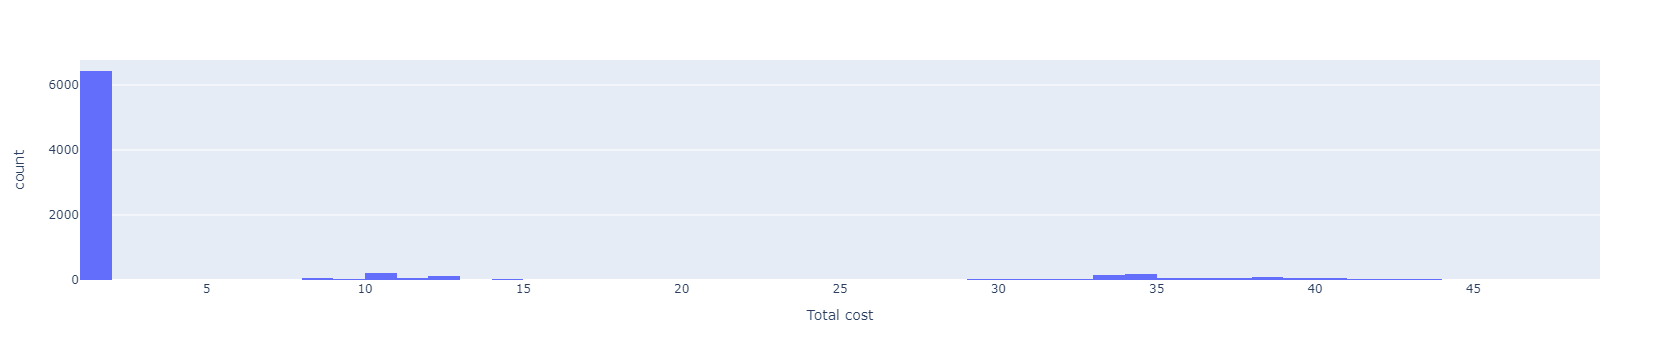

In [49]:
fig = px.histogram(df, x="Total cost")
fig.show()

### Correlation plot

Does not seem like any input strongly correlates with total cost. 

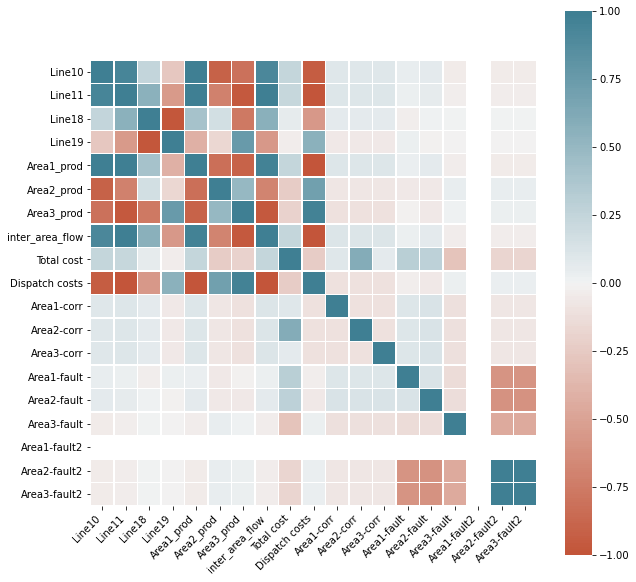

In [50]:
df_ = df[['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'inter_area_flow', 'fault', 'corr', 
          'Total cost', 'Dispatch costs', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2']]

corr = df_.corr()
fig, ax = plt.subplots(figsize=(10,10))  
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, linewidths=.5
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

## Run script

__NB!__ if you want .py-script to run with this imported dataframe, should not define `df` in script.

In [51]:
thresh = 10

In [52]:
%run -i "gcn_classification.py"

Number of training graphs: 5567
Number of validation graphs: 1537
Number of test graphs: 849
Epoch: 001, Train Acc: 0.8408, Validation Acc: 0.8608
Epoch: 002, Train Acc: 0.8646, Validation Acc: 0.8868
Epoch: 003, Train Acc: 0.8748, Validation Acc: 0.8972
Epoch: 004, Train Acc: 0.8775, Validation Acc: 0.9018
Epoch: 005, Train Acc: 0.8752, Validation Acc: 0.8959
Epoch: 006, Train Acc: 0.8750, Validation Acc: 0.8953
Epoch: 007, Train Acc: 0.8746, Validation Acc: 0.8953
Epoch: 008, Train Acc: 0.8617, Validation Acc: 0.8751
Epoch: 009, Train Acc: 0.8653, Validation Acc: 0.8809
Epoch: 010, Train Acc: 0.8762, Validation Acc: 0.8933
Epoch: 011, Train Acc: 0.8658, Validation Acc: 0.8874
Epoch: 012, Train Acc: 0.8646, Validation Acc: 0.8803
Epoch: 013, Train Acc: 0.8626, Validation Acc: 0.8770
Epoch: 014, Train Acc: 0.8662, Validation Acc: 0.8790
Epoch: 015, Train Acc: 0.8649, Validation Acc: 0.8790
Epoch: 016, Train Acc: 0.8651, Validation Acc: 0.8712
Epoch: 017, Train Acc: 0.8771, Validation A

# Results

## Convergence plot

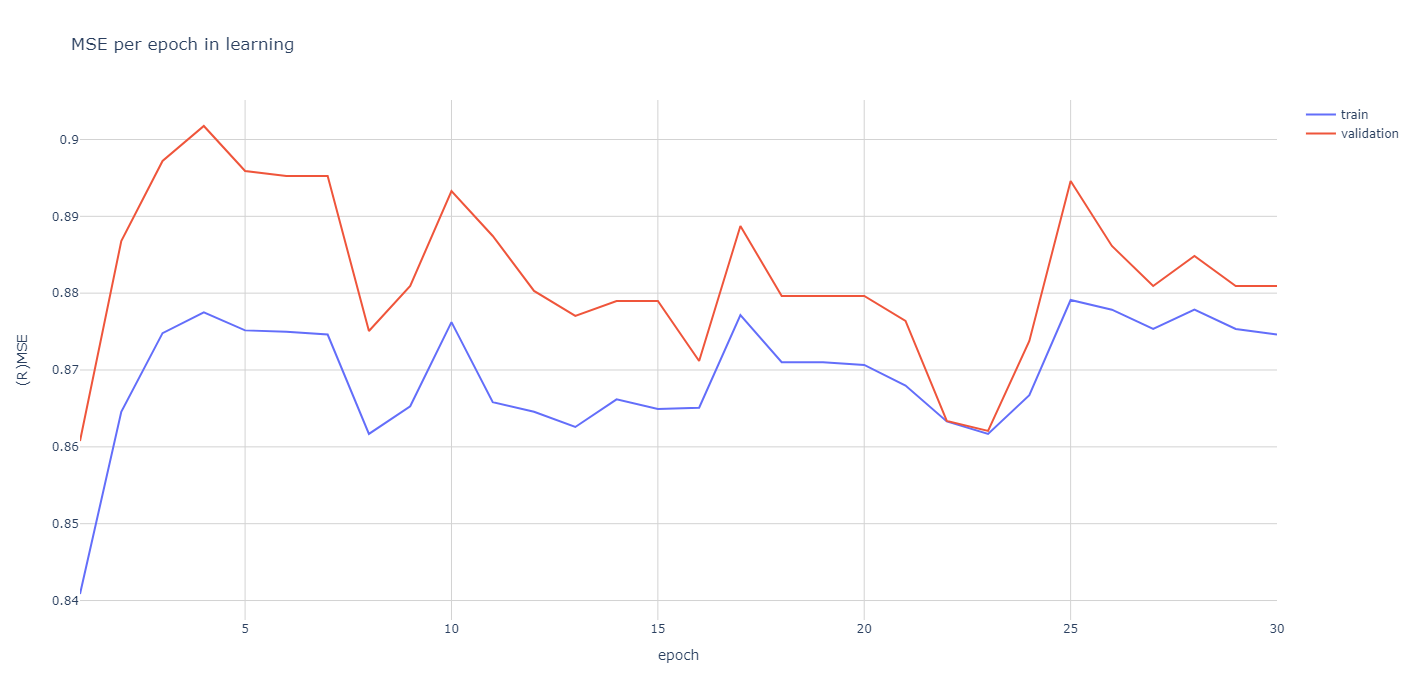

In [56]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"       # this sets its legend entry
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"       # this sets its legend entry
))

fig.update_layout(
    title="MSE per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="MSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = '(R)MSE',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

## ROC Curve (not representative unless sample size of both classes equal)

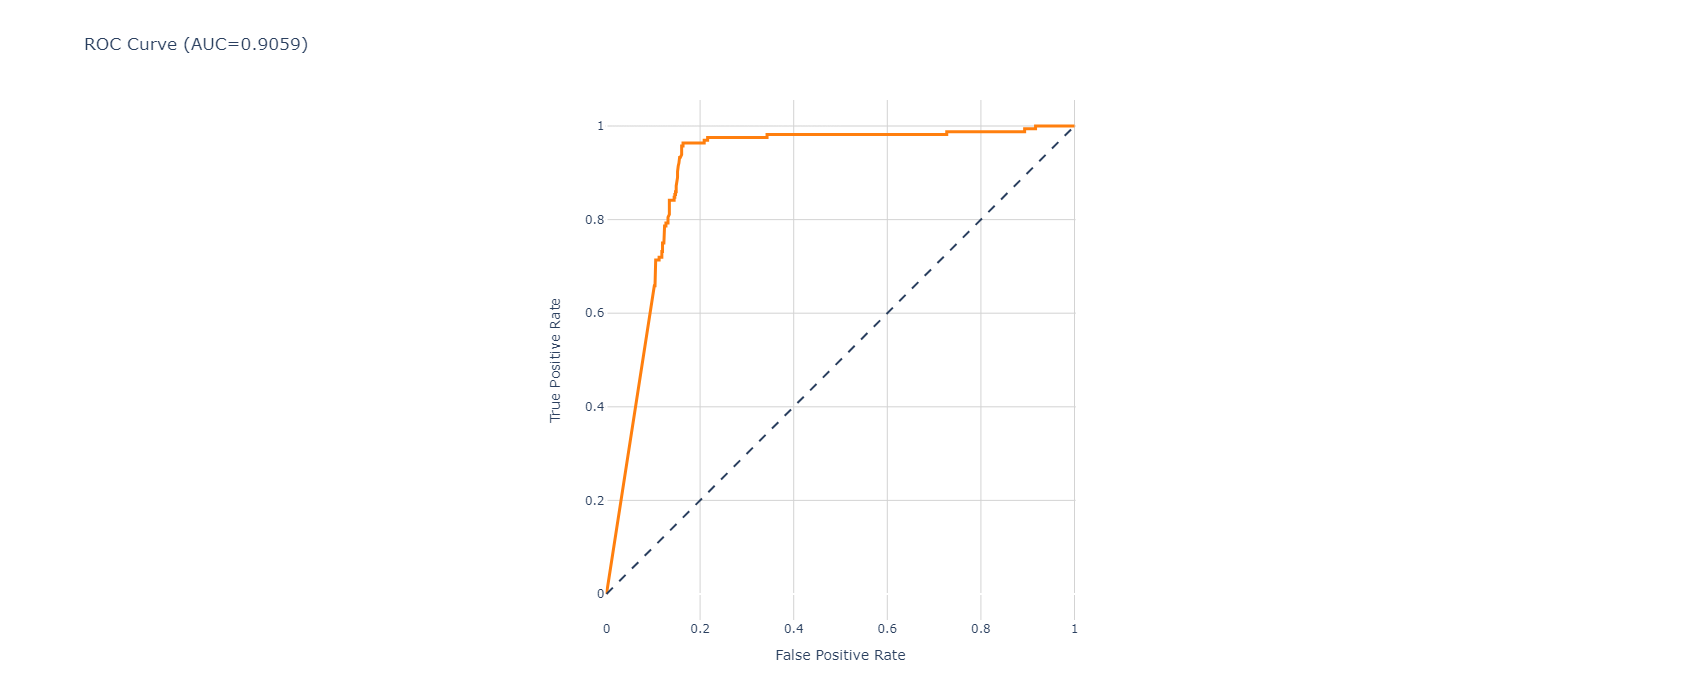

In [57]:
fpr, tpr, _ = roc_curve(y_target, y_prob)
auc_score = roc_auc_score(y_target, y_prob)

layout = go.Layout(
    title = f'ROC Curve (AUC={auc(fpr, tpr):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)
fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=0, x1=1, y0=0, y1=1
)


fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines', line=dict(color='#FF7F0E', width=3)))

fig.update_layout(
    xaxis_title='False Positive Rate',
    yaxis_title='True Positive Rate',
    yaxis=dict(scaleanchor="x", scaleratio=1),
    xaxis=dict(constrain='domain'),
    width=700, height=700
)
fig.show()

## Create confusion matrix

In [58]:
test_acc

0.8586572438162544

In [59]:
tn, fp, fn, tp = confusion_matrix(y_target, y_pred).ravel()
(tn, fp, fn, tp)

(571, 114, 6, 158)

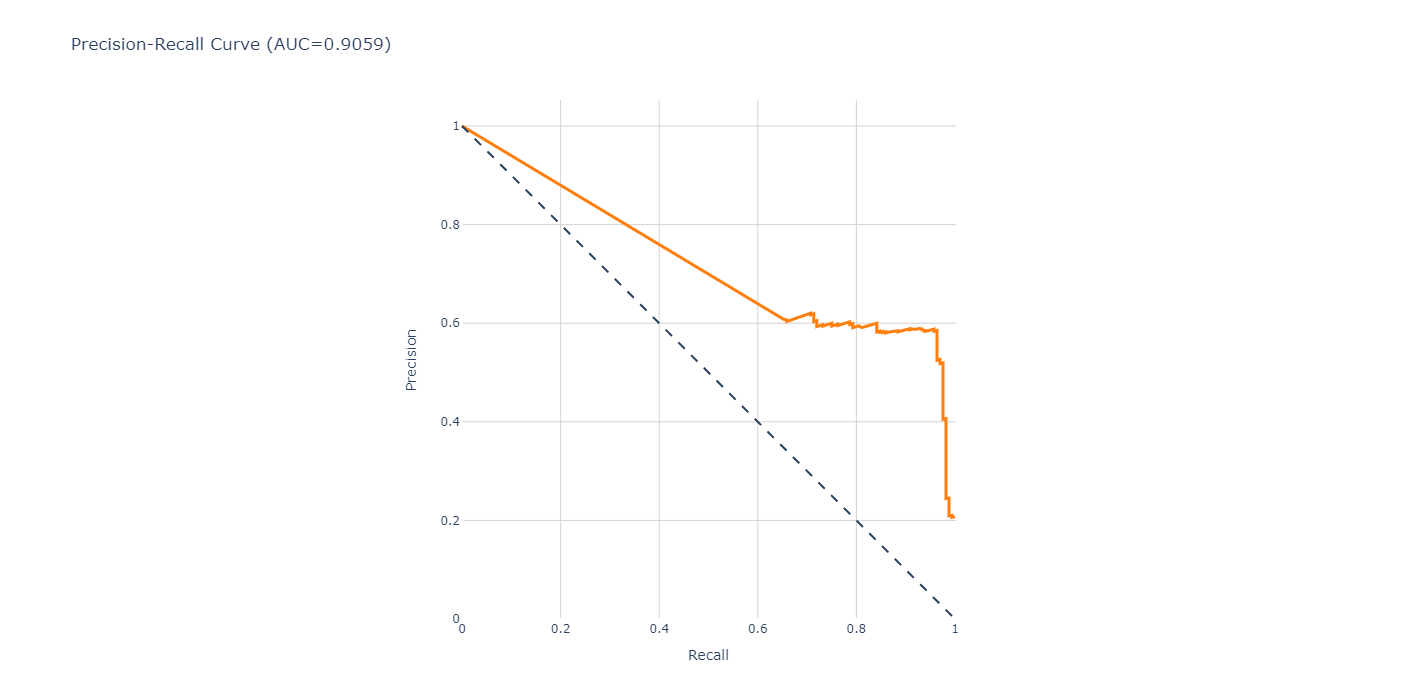

In [61]:
layout = go.Layout(
    title = f'Precision-Recall Curve (AUC={auc(fpr, tpr):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)
fig.add_shape(
    type='line', line=dict(dash='dash'),
    x0=0, x1=1, y0=1, y1=0
)


fig.add_trace(go.Scatter(x=recall, y=precision, mode='lines', line=dict(color='#FF7F0E', width=3)))

fig.update_layout(
    xaxis_title='Recall',
    yaxis_title='Precision',
    yaxis=dict(scaleanchor="x", scaleratio=1),
    xaxis=dict(constrain='domain'),
    width=700, height=700
)
fig.show()

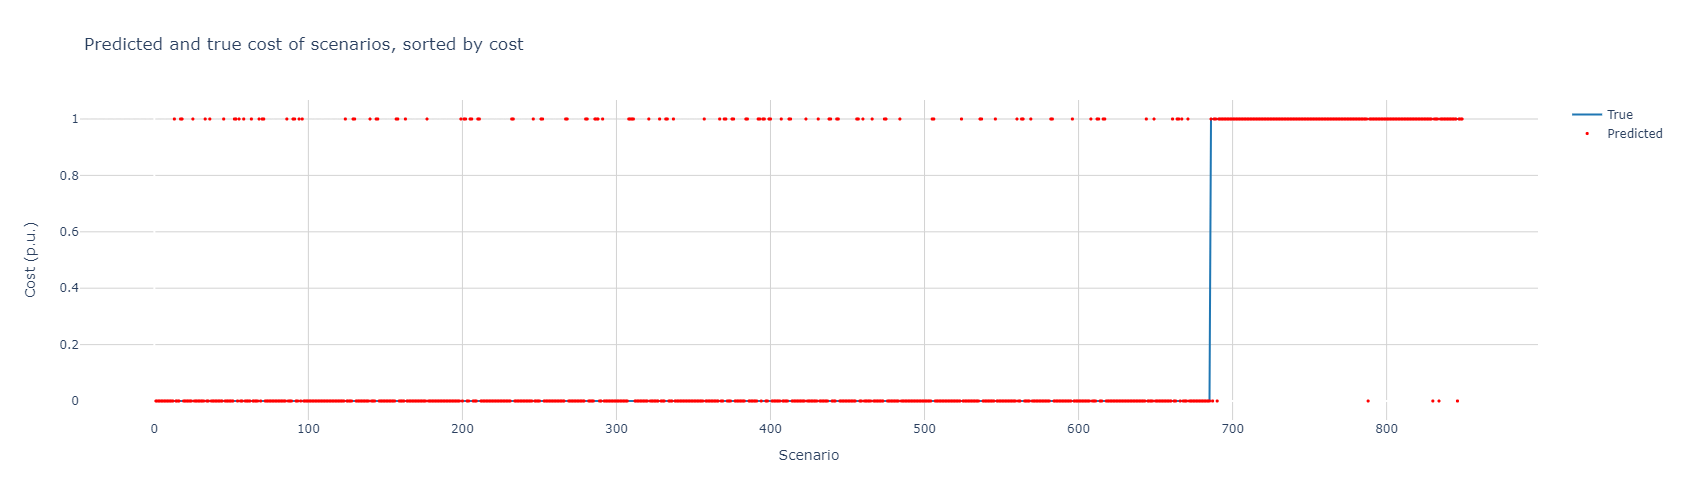

In [62]:
plot_df = df_results.sort_values(by=['target'])

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['pred'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()